[-0.75275929] -0.44822072637593674


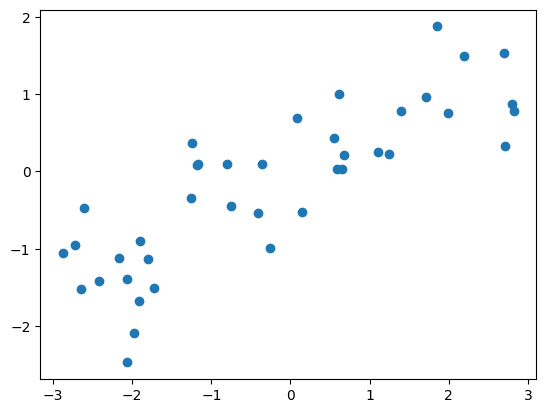

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

arr = np.load('/content/drive/MyDrive/운영/MBC/데이터분석_1기/수업/04_ML/data/make_wave.npz')
x = arr['x']
y = arr['y']
print(x[0],y[0])
plt.scatter(x,y)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
# 학습 완료
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=11)
reg = LinearRegression().fit(x_train,y_train)

In [ ]:
#예측해 보기
#x
x_val = np.array([-3,-2.5,-2,1.3,0.35,1,2,2.3,3]).reshape(-1,1)
#x_val
y_val = reg.predict(x_val)
y_val

array([-1.50923308, -1.27251635, -1.03579962,  0.52653079,  0.076769  ,
        0.38450075,  0.85793421,  0.99996425,  1.33136766])

1. 위 코드에서 내부적으로는 y=ax+b 를 통해 답을 내게 된다.
2. 즉, 트레이닝이라는 과정은 x를 통해 y 를 구하기 위한 a 와 b 의 값을 조정해 나가는 것이다.
3. 그 트레이닝을 통해서 얻어낸 최적의 값 a 는 coef_, b 는 intercept_

In [ ]:
print(f'coef : {reg.coef_} / intercept : {reg.intercept_}')
# coef : [0.47343346] / intercept : -0.08893270548874904
# y = ax+b 공식을 이용해 계산해 보면 predict(x_val) 와 같은 값이 나타난다.
result = reg.coef_*x_val + reg.intercept_
# print(y_val)
print(result.reshape(1,-1)[0])

coef : [0.47343346] / intercept : -0.08893270548874904
[-1.50923308 -1.27251635 -1.03579962  0.52653079  0.076769    0.38450075
  0.85793421  0.99996425  1.33136766]


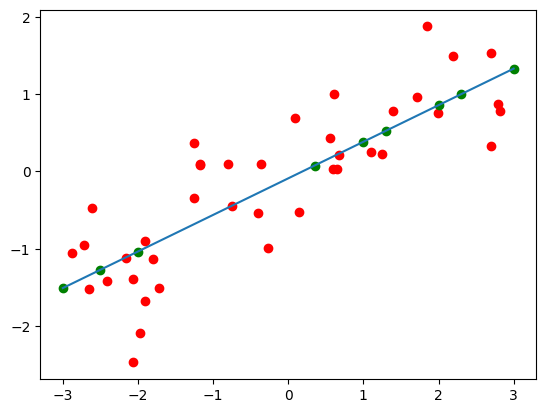

In [ ]:
# 이제 어떤 추세로 예측하는지 예측선을 그어보자
plt.scatter(x,y,c='red') # 데이터 분포
plt.scatter(x_val,y_val,c='green')# 예상 데이터

line = np.arange(-3,4)
# plt.plot(line,y=ax+b)
plt.plot(line,reg.coef_*line+reg.intercept_)

plt.show()

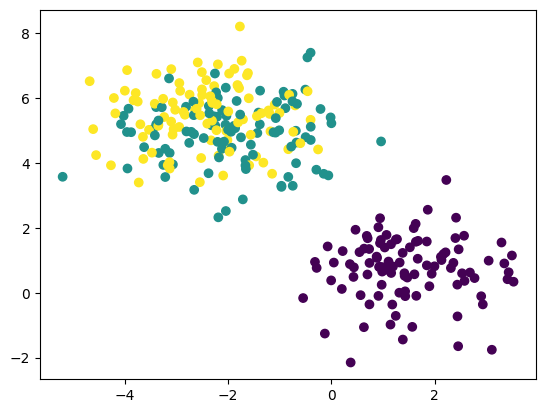

In [ ]:
# 그런데 이전의 분류 알고리즘과 비교해 보자
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
x,y = make_blobs(n_samples=300, n_features=2, centers=3)
plt.scatter(x[:,0],x[:,1],c=y)
plt.show()

계수(coef) : [ 0.53671891 -0.36016901]
절편(intercept):0.8421659204290463
[ 0.53671891 -0.36016901] 0.8421659204290463
[-0.09182033  0.07116589] -0.7143252692965429
[-0.1370789   0.14540909] -0.9916526735418072


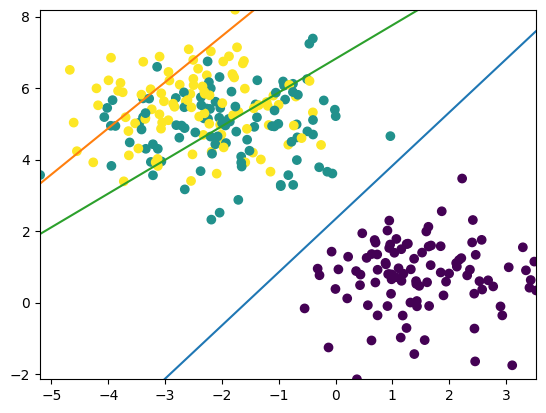

In [ ]:
from sklearn.svm import LinearSVC
import numpy as np
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=43)
svc = LinearSVC(C=0.1,penalty='l2', dual=True).fit(x_train,y_train)
print(f'계수(coef) : {svc.coef_[0]}')  # 기울기
print(f'절편(intercept):{svc.intercept_[0]}') # 방향

# y = ax+b 에서 a 값(계수)이 1개가 아니다?
plt.scatter(x[:,0],x[:,1],c=y)
line = np.linspace(-10,10)

for coef,inter in zip(svc.coef_,svc.intercept_):
  print(coef,inter)

  #y = -(intercept + coef[0]*x) / coef[1]
  # 그런데 여기서 x 는 line 이자나?
  # y = -(intercept + coef[0]*line) / coef[1]
  plt.plot(line, -(inter + coef[0]*line) / coef[1])

plt.xlim(x[:,0].min(),x[:,0].max())
plt.ylim(x[:,1].min(),x[:,1].max())
plt.show()

이렇게 계수가 여러개인 경우는 공식이 조금 달라진다.
*   계수[0] * 특성1 + 계수[1] * 특성2 + ... + 절편 = 0
*   coef[0] * x + coef[1] * y + intercept = 0

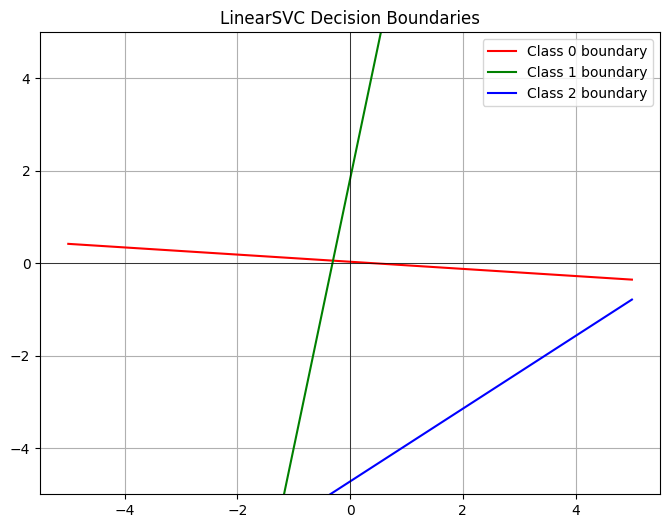

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC
import numpy as np
from sklearn.model_selection import train_test_split

# 데이터 설정
coef = np.array([[ 0.03506831,  0.45304155],
                 [-0.24599197,  0.04227203],
                 [ 0.24324805, -0.30895903]])
intercept = np.array([-0.01510705, -0.07701472, -1.45892604])

# x축 범위 설정 (데이터의 분포에 맞춰 조절하세요)
x_vals = np.linspace(-5, 5, 100)

plt.figure(figsize=(8, 6))

# 각 클래스별 라인 그리기
colors = ['r', 'g', 'b']
for i in range(len(intercept)):
    # y = -(a/b)x - (c/b)
    y_vals = -(coef[i][0] / coef[i][1]) * x_vals - (intercept[i] / coef[i][1])
    plt.plot(x_vals, y_vals, label=f'Class {i} boundary', color=colors[i])

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.ylim(-5, 5) # y축 범위 제한
plt.legend()
plt.title("LinearSVC Decision Boundaries")
plt.grid(True)
plt.show()